
# Assignment 1 — Reactive Agent: Moving Toward Light

### Objective
Simulate a simple reactive agent that moves toward a light source in a 2D grid.

### Basic Idea
A reactive agent chooses its next action using only the current situation.  
Here, the agent checks the position of the light and moves to the neighboring cell that brings it closer to the light.


### Step 1 — Import Required Libraries
We use `matplotlib` to visualize the agent's movement.

In [1]:

import matplotlib.pyplot as plt
from IPython.display import clear_output
import time



### Step 2 — Create the Grid

An 8×8 grid is used. The agent starts at the top-left corner and the light is placed at the bottom-right corner.


In [2]:

grid_size = 8

agent = (0, 0)
light = (7, 7)

print("Grid size:", grid_size, "x", grid_size)
print("Agent position:", agent)
print("Light position:", light)


Grid size: 8 x 8
Agent position: (0, 0)
Light position: (7, 7)



### Step 3 — Define the Reactive Rule

The agent can move up, down, left, or right.  
At every step, it selects a valid neighboring position with the smallest Manhattan distance from the light.


In [3]:

def manhattan_distance(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def get_valid_moves(position):
    row, col = position
    moves = [
        (row - 1, col),
        (row + 1, col),
        (row, col - 1),
        (row, col + 1)
    ]

    return [
        move for move in moves
        if 0 <= move[0] < grid_size and 0 <= move[1] < grid_size
    ]


def move_agent(position, target):
    valid_moves = get_valid_moves(position)
    return min(valid_moves, key=lambda move: manhattan_distance(move, target))


### Step 4 — Simulate the Agent
The agent repeatedly applies the reactive rule until it reaches the light.

In [4]:

agent_position = agent
path = [agent_position]

while agent_position != light:
    agent_position = move_agent(agent_position, light)
    path.append(agent_position)

print("Agent reached the light!")
print("Number of moves:", len(path) - 1)
print("Path:", path)


Agent reached the light!
Number of moves: 14
Path: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (7, 1), (7, 2), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7)]


### Step 5 — Display the Grid
`A` represents the agent, `L` represents the light, and `*` shows the path followed by the agent.

In [5]:

for row in range(grid_size):
    line = []
    for col in range(grid_size):
        position = (row, col)

        if position == agent:
            line.append("A")
        elif position == light:
            line.append("L")
        elif position in path:
            line.append("*")
        else:
            line.append(".")
    print(" ".join(line))


A . . . . . . .
* . . . . . . .
* . . . . . . .
* . . . . . . .
* . . . . . . .
* . . . . . . .
* . . . . . . .
* * * * * * * L


### Step 6 — Visualize the Agent's Path

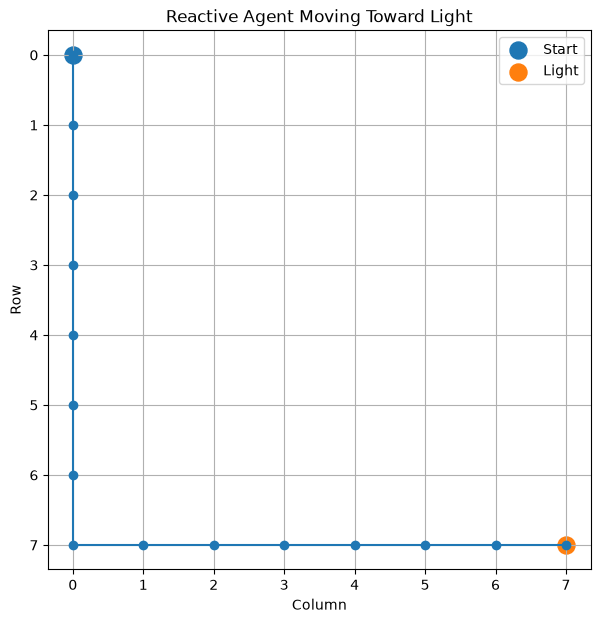

In [6]:

rows = [p[0] for p in path]
cols = [p[1] for p in path]

plt.figure(figsize=(7, 7))
plt.plot(cols, rows, marker="o")
plt.scatter(agent[1], agent[0], s=150, label="Start")
plt.scatter(light[1], light[0], s=150, label="Light")

plt.gca().invert_yaxis()
plt.xticks(range(grid_size))
plt.yticks(range(grid_size))
plt.grid(True)
plt.xlabel("Column")
plt.ylabel("Row")
plt.title("Reactive Agent Moving Toward Light")
plt.legend()
plt.show()


### Step 7 — Simple Animation
The animation shows the agent reacting to the light position one step at a time.

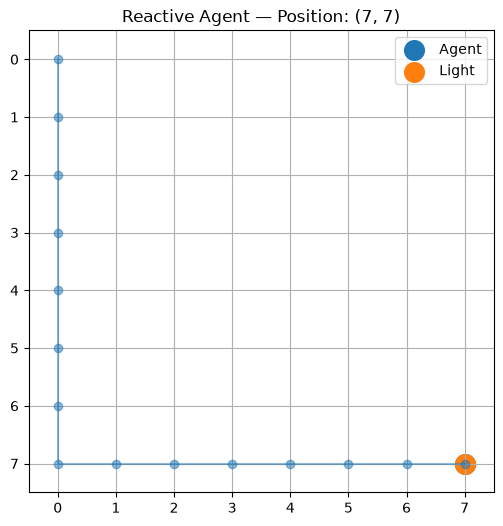

Animation completed.


In [7]:

for position in path:
    clear_output(wait=True)

    plt.figure(figsize=(6, 6))
    plt.xlim(-0.5, grid_size - 0.5)
    plt.ylim(grid_size - 0.5, -0.5)

    plt.xticks(range(grid_size))
    plt.yticks(range(grid_size))
    plt.grid(True)

    visited_rows = [p[0] for p in path[:path.index(position) + 1]]
    visited_cols = [p[1] for p in path[:path.index(position) + 1]]
    plt.plot(visited_cols, visited_rows, marker="o", alpha=0.5)

    plt.scatter(position[1], position[0], s=200, label="Agent")
    plt.scatter(light[1], light[0], s=200, label="Light")

    plt.title(f"Reactive Agent — Position: {position}")
    plt.legend()
    plt.show()

    time.sleep(0.25)

print("Animation completed.")



### Result

The reactive agent successfully reaches the light by repeatedly choosing the neighboring position that reduces its distance from the light.

### Conclusion
This demonstrates a **reactive agent** because the agent does not plan the complete route in advance. It simply observes the current target position and chooses the next action based on the current state.
